In [1]:
import pymupdf  # Imported as pymupdf or fitz
import numpy as np
from astropy.io import fits
import os
import cv2
import re
import matplotlib.pyplot as plt
from PIL import Image
import pytesseract

In [5]:

def pdf_to_images(pdf_path):
    # Open the PDF document
    doc = pymupdf.open(pdf_path)
    
    # Loop through each page
    for page_num in range(len(doc)):
        page = doc.load_page(page_num)
        
        # Render page to a pixmap (image)
        # Increase dpi (e.g., dpi=300) for higher quality
        pix = page.get_pixmap(dpi=300)
        
        # Save the image as PNG or JPG
        output_filename = f"/home/iron-man/Documents/long_term_reconstruction/PIL_cycle_18_19_png/page_{page_num + 424}.png"
        pix.save(output_filename)
        print(f"Saved: {output_filename}")

# Run the function
pdf_to_images("/home/iron-man/Documents/long_term_reconstruction/PIL_cycle_18_19.pdf")


Saved: /home/iron-man/Documents/long_term_reconstruction/PIL_cycle_18_19_png/page_424.png
Saved: /home/iron-man/Documents/long_term_reconstruction/PIL_cycle_18_19_png/page_425.png
Saved: /home/iron-man/Documents/long_term_reconstruction/PIL_cycle_18_19_png/page_426.png
Saved: /home/iron-man/Documents/long_term_reconstruction/PIL_cycle_18_19_png/page_427.png
Saved: /home/iron-man/Documents/long_term_reconstruction/PIL_cycle_18_19_png/page_428.png
Saved: /home/iron-man/Documents/long_term_reconstruction/PIL_cycle_18_19_png/page_429.png
Saved: /home/iron-man/Documents/long_term_reconstruction/PIL_cycle_18_19_png/page_430.png
Saved: /home/iron-man/Documents/long_term_reconstruction/PIL_cycle_18_19_png/page_431.png
Saved: /home/iron-man/Documents/long_term_reconstruction/PIL_cycle_18_19_png/page_432.png
Saved: /home/iron-man/Documents/long_term_reconstruction/PIL_cycle_18_19_png/page_433.png
Saved: /home/iron-man/Documents/long_term_reconstruction/PIL_cycle_18_19_png/page_434.png
Saved: /ho

page_407.png
cr number 139


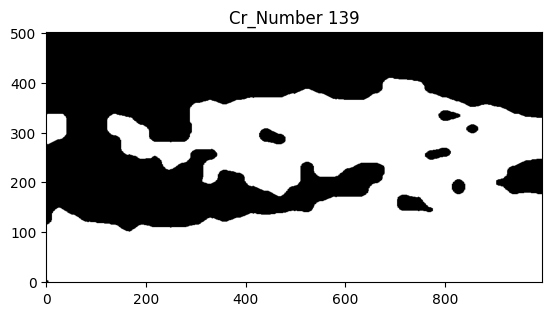

Saved: /home/iron-man/Documents/long_term_reconstruction/PIL_cycle_15_17_maps/1199.fits
Done!


In [32]:

# -----------------------------
# Input and output folders
# -----------------------------
input_folder = "/home/iron-man/Documents/long_term_reconstruction/PIL_cycle_15_17_png"
output_folder = "/home/iron-man/Documents/long_term_reconstruction/PIL_cycle_15_17_maps"

os.makedirs(output_folder, exist_ok=True)

# -----------------------------
# Crop coordinates
# (left, upper, right, lower)
# -----------------------------
left = 395
upper = 1722
right = 1391
lower = 2225







# print(img_array.shape)
# -----------------------------
# Crop all PNG files
# -----------------------------
for filename in sorted(os.listdir(input_folder))[:1]:   # some files are not created so i manuaaly correct it [819, 820, 825, 905, 945, 953, 960, 997, 1065, 1199]
    
    # filename= 'page_407.png'
    print(filename)
    if filename.lower().endswith(".png"):
        img_path = os.path.join(input_folder, filename)
           
        # Read image
        img = Image.open(img_path).convert("L")
        # extracted data from img 
        extracted_text = pytesseract.image_to_string(img)
        # print(extracted_text)
        match = re.search(r'N\s*(\d+)', extracted_text)  # text = "1956 - N1376"
        if match: # if img has cr number then it proceeds
            cr_number = match.group(1)
            print(f"cr number {cr_number}")
            # Crop  img 
            cropped = img.crop((left, upper, right, lower))
            cropped = np.array(cropped)
            # plt.imshow(cropped, cmap='gray', origin='lower')
            # plt.show()

            # plt.imshow(cropped==254, cmap='gray', origin='lower')
            # plt.show()      

            # plt.imshow(cropped==195, cmap='gray', origin='lower')
            # plt.show()

            # -------------------------
            # dilation
            # -------------------------
            kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5,5))
            dilated = cv2.dilate(cropped, kernel, iterations=3)
            # plt.title("Dilation")
            # plt.imshow(dilated, cmap='gray', origin='lower')
            # plt.show()
            # -------------------------
            # Erosion
            # -------------------------
            kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5,5))
            eroded = cv2.erode(dilated, kernel, iterations=2)
            # plt.title("Dilation--> erosion")
            # plt.imshow(eroded, cmap='gray', origin='lower')
            # plt.show()


        # Create output array
            fits_data = np.where(eroded == 254, 1, -1).astype(np.int16)
            fits_data = np.flipud(fits_data)
            plt.title(f"Cr_Number {cr_number}")
            plt.imshow(fits_data, cmap='gray', origin='lower')
            plt.show()
            # Save as FITS
            # cr_number =1199
            output_path = os.path.join(output_folder, f"{cr_number}.fits")

            hdu = fits.PrimaryHDU(fits_data)
            hdu.writeto(output_path, overwrite=True)

            print(f"Saved: {output_path}")
        
        # cv2.imwrite(os.path.join(output_folder, f"{cr_number}.png"), eroded)
print("Done!")

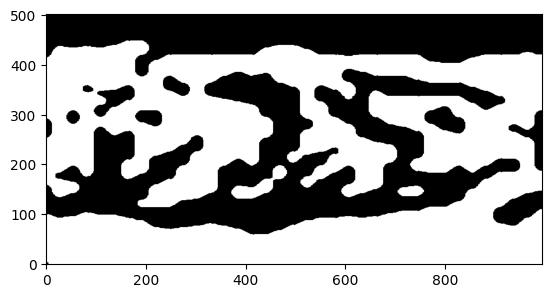

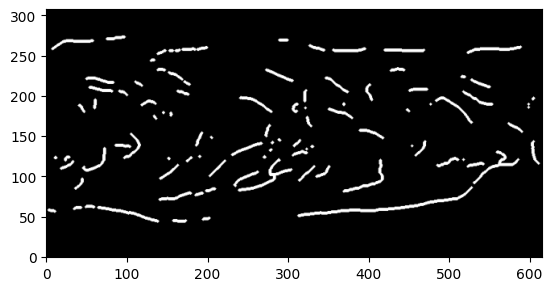

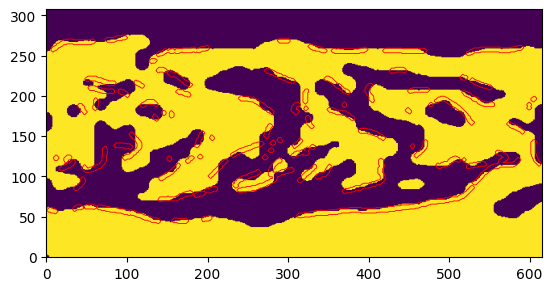

In [34]:
import cv2
from astropy.io import fits
import numpy as np
import matplotlib.pyplot as plt

# Read images
img1 = fits.getdata("/home/iron-man/Documents/long_term_reconstruction/PIL_cycle_18_19_maps/1250.fits")
img2 = cv2.imread("/home/iron-man/Documents/long_term_reconstruction/callibrated/Datasets/meudon_Halpha_CR_map/Meudon_cropped_data/1250.png",
                  cv2.IMREAD_GRAYSCALE)
img2 = np.flipud(img2)
plt.imshow(img1, cmap='gray', origin='lower')
plt.show()
plt.imshow(img2, cmap='gray', origin='lower')
plt.show()
# Resize FITS image to match PNG if needed
img1 = cv2.resize(img1.astype(np.float32),
                  (img2.shape[1], img2.shape[0]),
                  interpolation=cv2.INTER_NEAREST)

plt.imshow(img1, origin="lower")
# Contour overlay
plt.contour(
    img2,
    levels=[0.5],      # important for binary mask
    colors='red',
    linewidths=0.6,
    origin='lower'
)

cr number 815
cr number 816
cr number 817
cr number 818
cr number 4
cr number 141
cr number 821
cr number 822
cr number 823
cr number 824
cr number 147
cr number 826
cr number 827
cr number 828
cr number 829
cr number 830
cr number 831
cr number 832
cr number 833
cr number 834
cr number 835
cr number 836
cr number 837
cr number 838
cr number 839
cr number 840
cr number 841
cr number 842
cr number 843
cr number 844
cr number 845
cr number 846
cr number 847
cr number 848
cr number 849
cr number 850
cr number 851
cr number 852
cr number 853
cr number 854
cr number 855
cr number 856
cr number 857
cr number 858
cr number 859
cr number 860
cr number 861
cr number 862
cr number 863
cr number 864
cr number 865
cr number 866
cr number 867
cr number 868
cr number 869
cr number 870
cr number 871
cr number 872
cr number 873
cr number 874
cr number 875
cr number 876
cr number 877
cr number 878
cr number 879
cr number 880
cr number 881
cr number 882
cr number 883
cr number 884
cr number 885
cr numbe

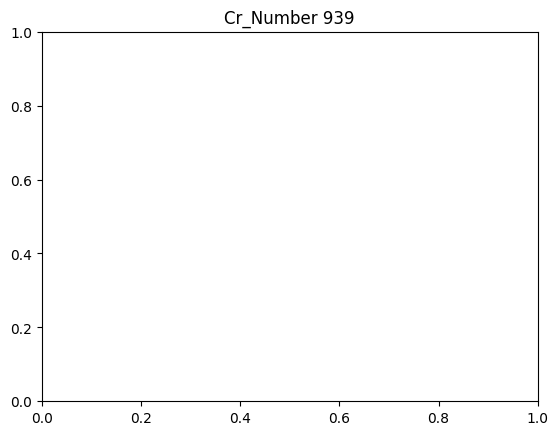

In [31]:


# -----------------------------
# Input and output folders
# -----------------------------
input_folder = "/home/iron-man/Documents/long_term_reconstruction/callibrated/Datasets/PIL_cycle_15_19_png"
output_folder = "/home/iron-man/Documents/long_term_reconstruction/callibrated/Datasets/PIL_cycle_15_19_maps/cycle_15"

os.makedirs(output_folder, exist_ok=True)

# -----------------------------
# Crop coordinates
# (left, upper, right, lower)
# -----------------------------
left = 395
upper = 1722
right = 1391
lower = 2225







# print(img_array.shape)
# -----------------------------
# Crop all PNG files
# -----------------------------
for page in range(1,717)[:]:   # some files' names are wrong, so I manually correct them 
    
    filename= f'page_{page}.png'
    # print(filename)
    if filename.lower().endswith(".png"):
        img_path = os.path.join(input_folder, filename)
           
        # Read image
        img = Image.open(img_path).convert("L")
        # extracted data from img 
        extracted_text = pytesseract.image_to_string(img)
        # print(extracted_text)
        match = re.search(r'N\s*(\d+)', extracted_text)  # text = "1956 - N1376"
        if match: # if img has cr number then it proceeds
            cr_number = match.group(1)
            print(f"cr number {cr_number}")
            # Crop  img 
            cropped = img.crop((left, upper, right, lower))
            cropped = np.array(cropped)
            # plt.imshow(cropped, cmap='gray', origin='lower')
            # plt.show()
            
            # plt.imshow(cropped==254, cmap='gray', origin='lower')
            # plt.title("254 pixel value")
            # plt.show()      

            # plt.imshow(cropped==195, cmap='gray', origin='lower')
            # plt.title("195 pixel value")
            # plt.show()

            # -------------------------
            # dilation
            # -------------------------
            kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5,5))
            dilated = cv2.dilate(cropped, kernel, iterations=3)
            # plt.title("Dilation")
            # plt.imshow(dilated, cmap='gray', origin='lower')
            # plt.show()
            # -------------------------
            # Erosion
            # -------------------------
            kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5,5))
            eroded = cv2.erode(dilated, kernel, iterations=2)
            # plt.title("Dilation--> erosion")
            # plt.imshow(eroded, cmap='gray', origin='lower')
            # plt.show()


        # Create output array
            fits_data = np.where(eroded == 195, 4, 7).astype(np.int16)
            fits_data = np.flipud(fits_data)
            plt.title(f"Cr_Number {cr_number}")
            # plt.imshow(fits_data, cmap='gray', origin='lower')
            # plt.show()
            original = fits_data.copy()

            # Dilate
            kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3,3))
            dilated = cv2.dilate(original, kernel, iterations=2)
            # plt.imshow(dilated, cmap='gray', origin='lower')
            # plt.show()
            # Mark only new pixels created by dilation
            result = dilated.copy()
            result[(dilated == 7) & (original != 7)] = 9
            result = np.where(result == 4, 7,
                   np.where(result == 7, 4, result))
            plt.imshow(result, cmap='gray', origin='lower')
            plt.colorbar()
            plt.show()
            # Save as FITS
            # cr_number =1199
            output_path = os.path.join(output_folder, f"{cr_number}.fits")

            hdu = fits.PrimaryHDU(result)
            hdu.writeto(output_path, overwrite=True)

            print(f"Saved: {output_path}")
        
        # cv2.imwrite(os.path.join(output_folder, f"{cr_number}.png"), eroded)
print("Done!")

In [21]:
# import os

# input_folder = "/home/iron-man/Documents/long_term_reconstruction/callibrated/Datasets/PIL_cycle_15_19_maps/cycle_18"

# # Read CR numbers from filenames
# cr_list = []
# for filename in os.listdir(input_folder):
#     if filename.endswith(".fits"):   # or remove this if other extensions
#         cr = int(os.path.splitext(filename)[0])
#         cr_list.append(cr)

# # Sort the list
# cr_list = sorted(cr_list)

# # Expected CR numbers
# expected = set(range(1215,1355))   # 1215 is excluded, so this gives 815–1214

# # Existing CR numbers
# existing = set(cr_list)

# # Missing CR numbers
# missing = sorted(expected - existing)

# print(f"Total expected : {len(expected)}")
# print(f"Total found    : {len(existing)}")
# print(f"Total missing  : {len(missing)}")

# print("\nMissing CR numbers:")
# print(missing)

Total expected : 140
Total found    : 140
Total missing  : 5

Missing CR numbers:
[1221, 1232, 1240, 1267, 1275]


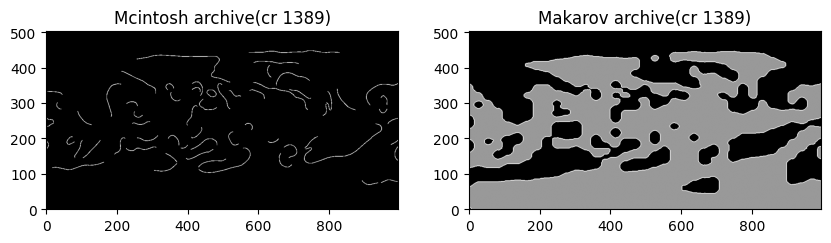

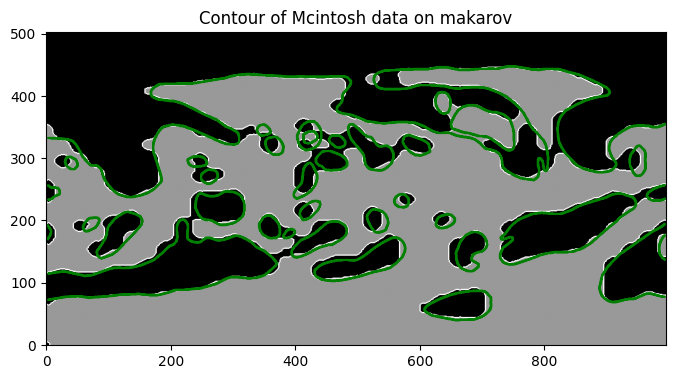

In [42]:
import os
from skimage.transform import resize
from astropy.io import fits
import matplotlib.pyplot as plt

folder1 = "/home/iron-man/Documents/long_term_reconstruction/callibrated/Datasets/PIL_files"
folder2 = "/home/iron-man/Documents/long_term_reconstruction/callibrated/Datasets/PIL_cycle_15_19_maps/cycle_19"
folder3 = "/home/iron-man/Documents/long_term_reconstruction/callibrated/train/pil/"
# filename = "1287.fits"

# Read FITS files
data1 = fits.getdata(os.path.join(folder1, "cr1389.fits.gz"))
data2 = fits.getdata(os.path.join(folder2, "1389.fits"))
data3 = fits.getdata(os.path.join(folder3, "19750421_0211.fits"))
# Plot
plt.figure(figsize=(10, 8))
data1 = resize(data1, (data2.shape[0], data2.shape[1]), order=0, preserve_range=True).astype(data1.dtype)
plt.subplot(1, 2, 1)
# (data1==8)|(data1==9))[:,:]
plt.imshow(data1==9,cmap='gray', origin='lower')
plt.title("Mcintosh archive(cr 1389)")
# my_list=((data1==8)|(data1==9))[:,810:811]
# print(sum(bool(x) for x in my_list))
plt.subplot(1, 2, 2)
plt.imshow(data2, cmap='gray', origin='lower')
plt.title("Makarov archive(cr 1389)")

# plt.subplot(1, 3, 3)
# plt.imshow(data3==8, cmap='gray', origin='lower')
# plt.title("Folder 3")
plt.figure(figsize=(8, 6))

# Show background image
plt.imshow(data2,cmap='gray', origin='lower')

# Overlay contour from data1
plt.contour(
    (data1==8)|(data1==9),
    levels=[0.9],      # if data1 is binary (0/1)
    colors='green',
    linewidths=1.5,
    origin='lower'
)

plt.title("Contour of Mcintosh data on makarov")
plt.show()

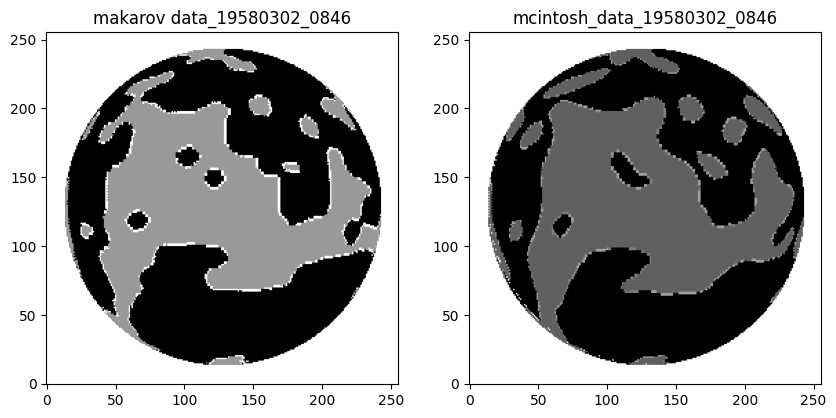

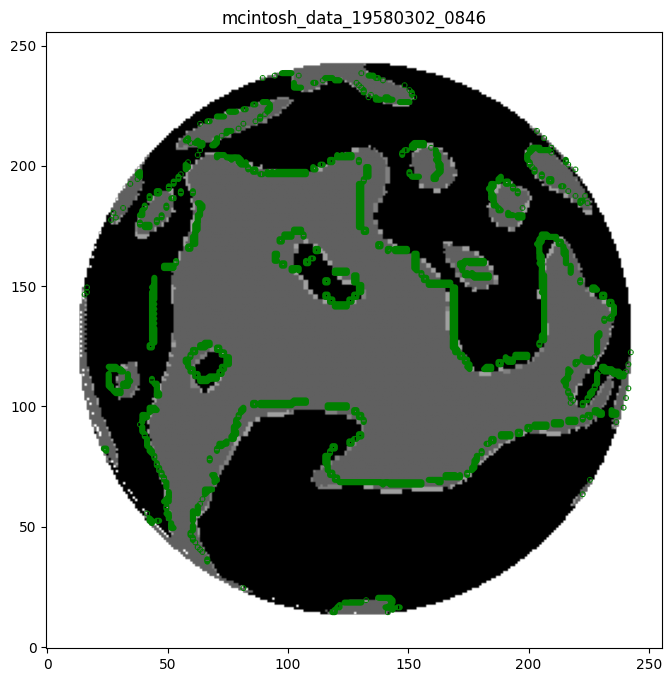

In [73]:
import os
from skimage.transform import resize
from astropy.io import fits
import matplotlib.pyplot as plt
folder2 = "/home/iron-man/Documents/long_term_reconstruction/callibrated/Cropped_pil_(1950_1975)/1958/03"
folder3 = "/home/iron-man/Documents/long_term_reconstruction/callibrated/Cropped_pil/1958/03"


# Read FITS files
data2 = fits.getdata(os.path.join(folder2, "19580302_0846.fits"))
data3 = fits.getdata(os.path.join(folder3, "19580302_0846.fits"))

plt.figure(figsize=(10, 8))
plt.subplot(1,2,1)
plt.imshow(data2, cmap='gray', origin='lower')
plt.title("makarov data_19580302_0846")
# plt.show()
plt.subplot(1,2,2)
plt.imshow(data3, cmap='gray', origin='lower')
plt.title("mcintosh_data_19580302_0846")
plt.show()

plt.figure(figsize=(10, 8))
plt.imshow(data3, cmap='gray', origin='lower')
plt.title("mcintosh_data_19580302_0846")


plt.contour(
    data2==9,
    levels=[0.9],      # important for binary mask
    colors='green',
    linewidths=4,
    origin='lower'
)
plt.show()

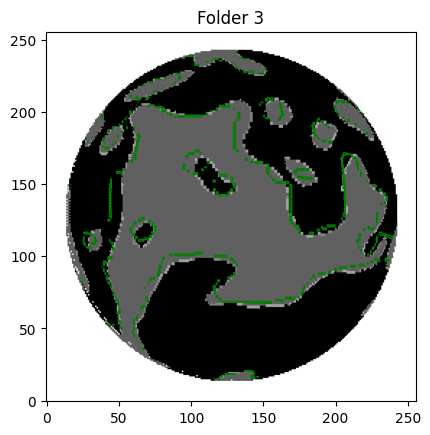

In [50]:
import os
from skimage.transform import resize
from astropy.io import fits
import matplotlib.pyplot as plt
folder2 = "/home/iron-man/Documents/long_term_reconstruction/callibrated/Cropped_pil_(1950_1975)/1958/03"
folder3 = "/home/iron-man/Documents/long_term_reconstruction/callibrated/Cropped_pil/1958/03"


# Read FITS files
data2 = fits.getdata(os.path.join(folder2, "19580302_0846.fits"))
data3 = fits.getdata(os.path.join(folder3, "19580302_0846.fits"))
plt.imshow(data3, cmap='gray', origin='lower')
plt.title("Folder 3")

plt.contour(
    data2==9,
    levels=[0.9],      # important for binary mask
    colors='green',
    linewidths=1,
    origin='lower'
)

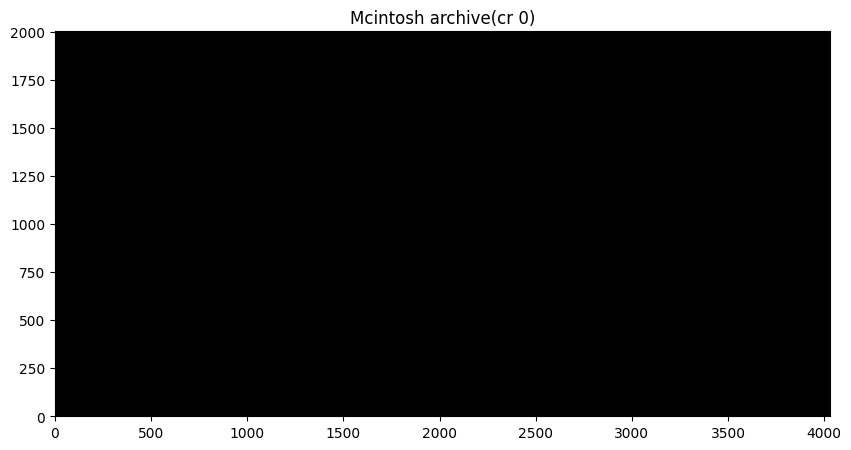

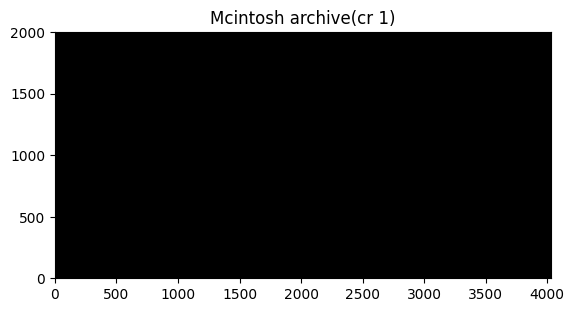

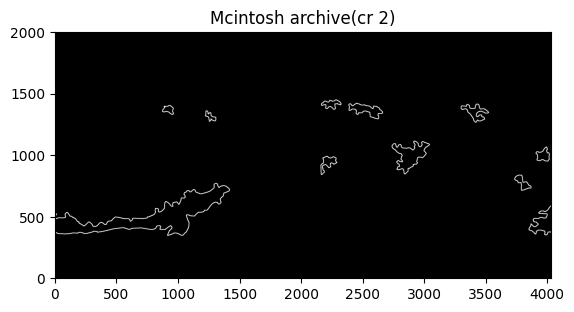

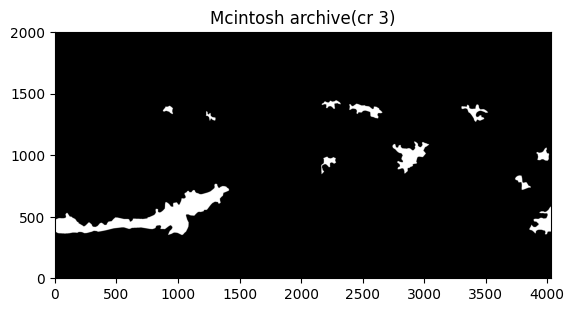

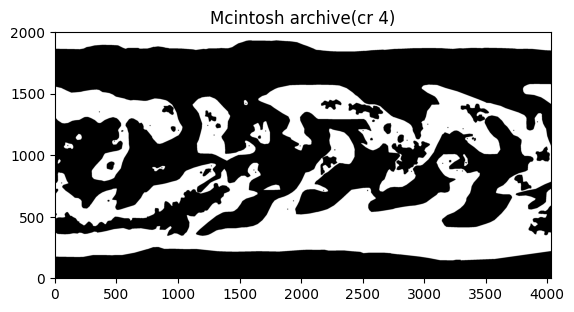

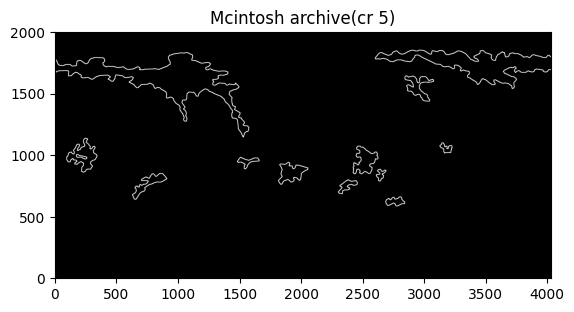

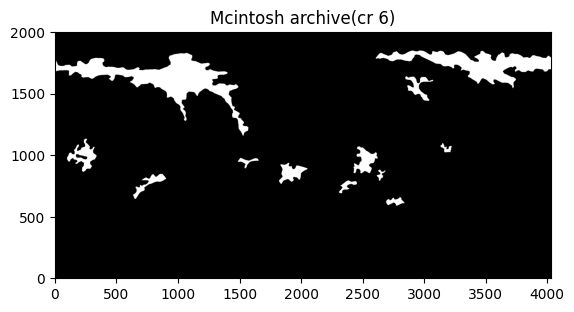

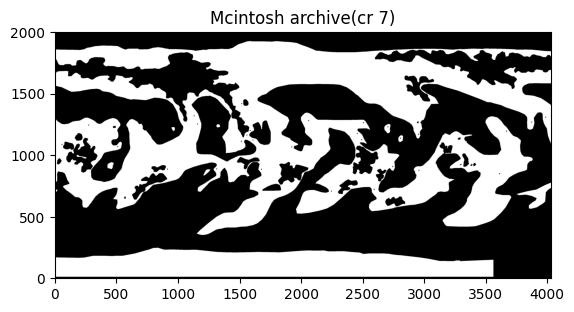

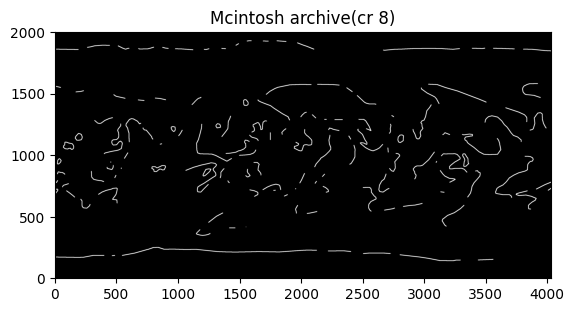

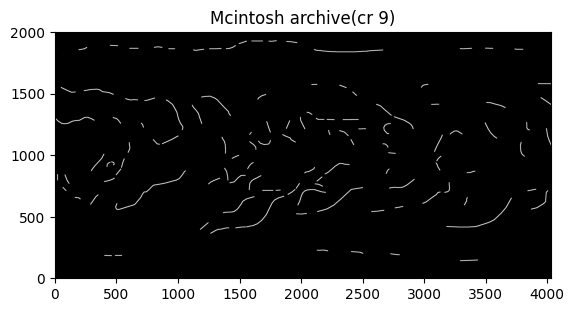

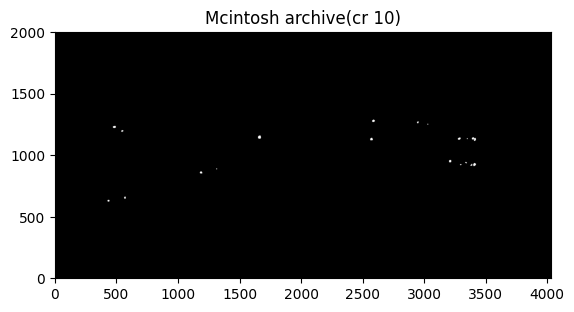

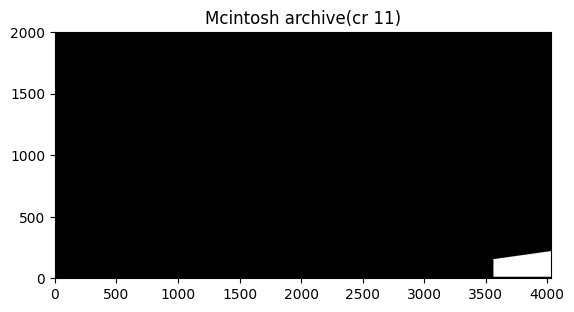

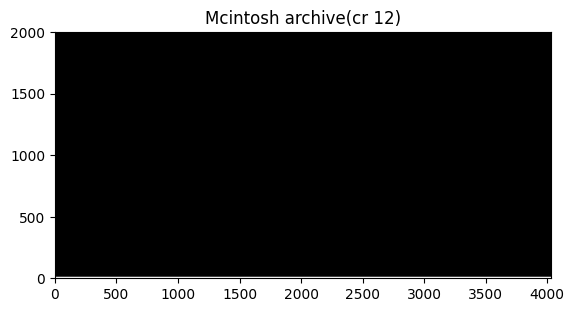

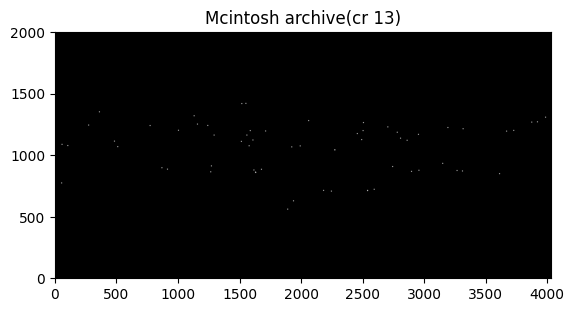

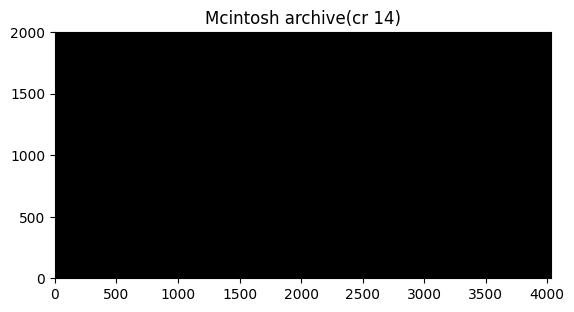

In [24]:
import os
from skimage.transform import resize
from astropy.io import fits
import matplotlib.pyplot as plt

folder1 = "/home/iron-man/Documents/long_term_reconstruction/callibrated/Datasets/PIL_files"

# Read FITS files
data1 = fits.getdata(os.path.join(folder1, "cr1699.fits.gz"))
plt.figure(figsize=(10, 8))
# data1 = resize(data1, (data2.shape[0], data2.shape[1]), order=0, preserve_range=True).astype(data1.dtype)
for i in range(0,15):
    
    plt.imshow(data1==i,cmap='gray', origin='lower')
    plt.title(f"Mcintosh archive(cr {i})")
    plt.show()


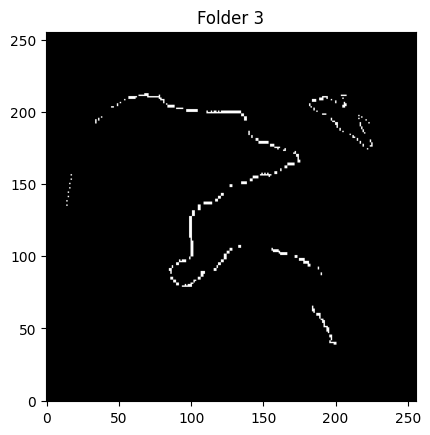

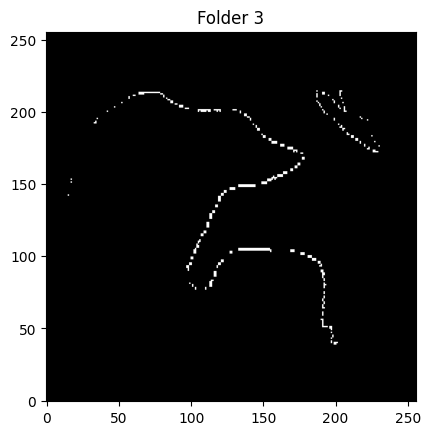

In [38]:
import os
from skimage.transform import resize
from astropy.io import fits
import matplotlib.pyplot as plt
folder2 = "/home/iron-man/Documents/long_term_reconstruction/callibrated/Cropped_pil_(1914_1964)/1954/12"
folder3 = "/home/iron-man/Documents/long_term_reconstruction/callibrated/Cropped_pil_(1955_2005)/1954/12"


# Read FITS files
data2 = fits.getdata(os.path.join(folder2, "19541228_1436.fits"))
data3 = fits.getdata(os.path.join(folder3, "19541228_1436.fits"))
plt.imshow(data2==9, cmap='gray', origin='lower')
plt.title("Folder 3")
plt.show()
plt.imshow((data3==8)|(data3==9), cmap='gray', origin='lower')
plt.title("Folder 3")
plt.show()

# plt.contour(
#     data2==9,
#     levels=[0.9],      # important for binary mask
#     colors='green',
#     linewidths=1,
#     origin='lower'
# )

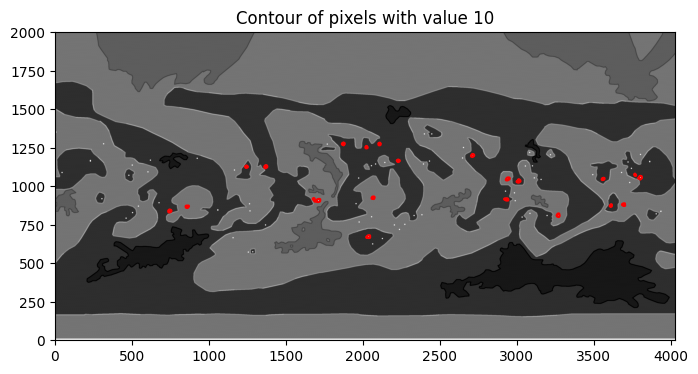

In [57]:
import numpy as np
import matplotlib.pyplot as plt
img= data1.copy()
# Binary mask of pixels with value 10
mask = (img == 10)

plt.figure(figsize=(8, 6))

# Show original image
plt.imshow(img, cmap='gray', origin='lower')

# Draw contour of value-10 regions
plt.contour(
    mask.astype(float),
    levels=[0.5],
    colors='red',
    linewidths=1.5,
    origin='lower'
)

plt.title("Contour of pixels with value 10")
plt.show()

In [54]:
import numpy as np

unique_values = np.unique(img)
print(unique_values)

[ 2  3  4  5  6  7  8  9 10 12 13]


Shape: (503, 996)
Data type: >i2
Unique values: [-1  1]


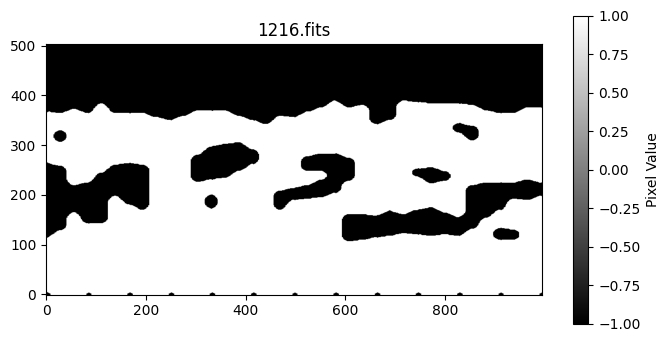

In [27]:
import os
from astropy.io import fits
import matplotlib.pyplot as plt
import numpy as np

# Folder containing the FITS file
folder = "/home/iron-man/Documents/long_term_reconstruction/callibrated/Datasets/PIL_before_cycle_19/PIL_cycle_18_19_maps"

# File path
file_path = os.path.join(folder, "1216.fits")

# Read FITS data
data = fits.getdata(file_path)

# Print some information
print("Shape:", data.shape)
print("Data type:", data.dtype)
print("Unique values:", np.unique(data))

# Display the image
plt.figure(figsize=(8, 4))
plt.imshow(data, cmap="gray", origin="lower")
plt.colorbar(label="Pixel Value")
plt.title("1216.fits")
plt.show()

Shape: (503, 996)
Data type: >i2
Unique values: [4 7 9]


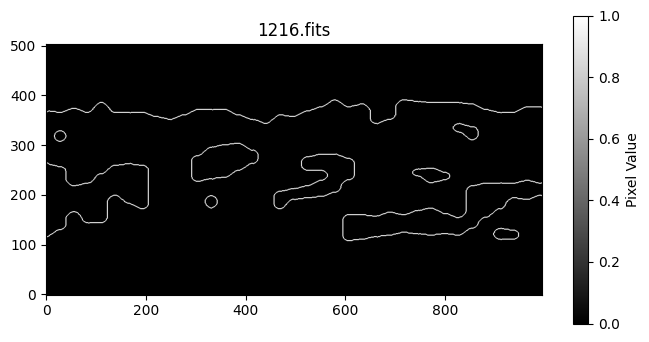

In [29]:

import os
from astropy.io import fits
import matplotlib.pyplot as plt
import numpy as np

# Folder containing the FITS file
folder = "/home/iron-man/Documents/long_term_reconstruction/callibrated/Datasets/PIL_cycle_15_19_maps/cycle_18"

# File path
file_path = os.path.join(folder, "1216.fits")

# Read FITS data
data = fits.getdata(file_path)

# Print some information
print("Shape:", data.shape)
print("Data type:", data.dtype)
print("Unique values:", np.unique(data))

# Display the image
plt.figure(figsize=(8, 4))
plt.imshow(data==9, cmap="gray", origin="lower")
plt.colorbar(label="Pixel Value")
plt.title("1216.fits")
plt.show()
